Attempting to achieve scaling of Turing patterns by following Werner 2015: https://arxiv.org/pdf/1411.2359.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import animation
import sys
np.random.seed(0)

In [12]:
def construct_lap_reflect(nx):
    '''Construct laplacian operator with reflecting BCs'''
    
    lap = -2*np.diag(np.ones(nx)) + 1*np.diag(np.ones(nx-1), 1) + 1*np.diag(np.ones(nx-1), -1)
    
    lap[0,1] = 2    # Reflecting BCs
    lap[-1,-2] = 2 
    
    return lap
    

def integrate_classical_explicit(a0, b0, params, nx, dx, niter, dt, bc='reflect'):
    '''Integrate the classical Turing PDEs using an explicit Euler scheme.'''
    
    if bc=='reflect':
        lap = construct_lap_reflect(nx)
        
    a_stored = np.zeros((nx, niter))
    b_stored = np.zeros((nx, niter))
    
    a_stored[:,0] = a0
    b_stored[:,0] = b0 
    
    alpha_a, alpha_b, beta_a, beta_b, d_a, d_b, h = params
    for i in range(1, niter):
        if int(100*i/niter) > int(100*(i-1)/niter):
            sys.stdout.write("\rIteration {0}/{1} ({2}%)".format(i, niter, int(100*i/niter)))
            sys.stdout.flush()
    
        a = a_stored[:,i-1]
        b = b_stored[:,i-1]
        
        p = a** h / (a**h + b**h)
        a_stored[:,i] = a + dt * (alpha_a * p - beta_a * a + d_a * lap@a/dx**2) # forward Euler
        b_stored[:,i] = b + dt * (alpha_b * p - beta_b * b + d_b * lap@b/dx**2)
        
        
    return a_stored, b_stored
    

In [8]:
# attempt integration
nx = 100
dx = .1
l = nx*dx
niter = 500000
dt = 0.0001

params = (1, 4, 1, 2, 1, 30, 5)

a0, b0 = np.random.uniform(0.1,0.2,nx), np.random.uniform(0.1,1,nx)

a_stored, b_stored = integrate_classical_explicit(a0, b0, params, nx, dx, niter, dt, bc='reflect')

np.savez_compressed('saved_outputs/classical_dx={:.1f}.npz'.format(dx), a=a_stored[:,-1], b=b_stored[:,-1])

Iteration 495000/500000 (99%)

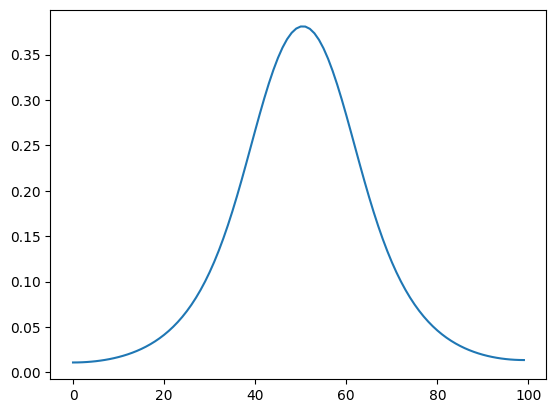

In [25]:
dx = .1
a_toplot = np.load('saved_outputs/classical_dx={:.1f}.npz'.format(dx))['a']
plt.plot(a_toplot)
plt.show()
# animation.animate_2d_array(a_stored[:,::5000])

I indeed see the same patterned steady-states as Werner, and the non-scaling of the pattern.

Now try my scheme of adiabatically eliminating E. I'm going to try it with an explicit scheme first, but the nonlinear terms may render that too unstable. We'll see.

In [13]:
def integrate_eliminated_explicit(a0, b0, params, nx, dx, niter, dt, bc='reflect'):
    '''
    Integrate the Turing PDEs with nonlinear degradation 
    derived from adiabatically eliminating Werner's E 
    using an explicit Euler scheme.
    '''
    
    if bc=='reflect':
        lap = construct_lap_reflect(nx)
        
    a_stored = np.zeros((nx, niter))
    b_stored = np.zeros((nx, niter))
    
    a_stored[:,0] = a0
    b_stored[:,0] = b0 
    
    alpha_a, alpha_b, beta_a, beta_b, d_a, d_b, h = params
    for i in range(1, niter):
        
        if int(100*i/niter) > int(100*(i-1)/niter):
            sys.stdout.write("\rIteration {0}/{1} ({2}%)".format(i, niter, int(100*i/niter)))
            sys.stdout.flush()
        
        a = a_stored[:,i-1]
        b = b_stored[:,i-1]
        
        p = a** h / (a**h + b**h)
        a_stored[:,i] = a + dt * (alpha_a * p - beta_a * a * b + d_a * lap@a/dx**2) # forward Euler
        b_stored[:,i] = b + dt * (alpha_b * p - beta_b * b * b + d_b * lap@b/dx**2)
        
        
    return a_stored, b_stored

In [18]:
# attempt integration
nx = 100
dx = .5
l = nx*dx
niter = 1000000
dt = 0.0001

params = (1, 4, 0.2, 0.4, 1, 30, 5)

a0, b0 = np.random.uniform(0.1,0.2,nx), np.random.uniform(0.1,1,nx)

a_stored, b_stored = integrate_eliminated_explicit(a0, b0, params, nx, dx, niter, dt, bc='reflect')

np.savez_compressed('saved_outputs/nonlinear_dx={:.1f}.npz'.format(dx), a=a_stored[:,-1], b=b_stored[:,-1], a_stored=a_stored[:,::500], b_stored=b_stored[:,::500])

Iteration 990000/1000000 (99%)

In [19]:
dx = .5
a_toplot = np.load('saved_outputs/nonlinear_dx={:.1f}.npz'.format(dx))['a_stored']
# plt.plot(b_toplot)
# plt.show()
animation.animate_2d_array(a_toplot)

Animation size has reached 20982122 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


It doesn't scale like I'd hoped, though it does appear to make the increase of the pattern a bit slower than the classical case (but that could just be by a factor of 2 or something). So the dynamics or at least spatial dependence of E is important somehow.

Now I try Werner's scheme, including the full dynamics for E.

In [50]:
def integrate_werner_explicit(a0, b0, e0, params, nx, dx, niter, dt, bc='reflect'):
    '''
    Integrate the Turing PDEs with Werner's E
    using an explicit Euler scheme.
    '''
    
    if bc=='reflect':
        lap = construct_lap_reflect(nx)
        
    a_stored = np.zeros((nx, niter))
    b_stored = np.zeros((nx, niter))
    e_stored = np.zeros((nx, niter))
    
    a_stored[:,0] = a0
    b_stored[:,0] = b0 
    e_stored[:,0] = e0 
    
    alpha_a, alpha_b, alpha_e, kappa_a, kappa_b, kappa_e, d_a, d_b, d_e, h = params
    for i in range(1, niter):
        
        if int(100*i/niter) > int(100*(i-1)/niter):
            sys.stdout.write("\rIteration {0}/{1} ({2}%)".format(i, niter, int(100*i/niter)))
            sys.stdout.flush()
        
        a = a_stored[:,i-1]
        b = b_stored[:,i-1]
        e = e_stored[:,i-1]
        
        p = a** h / (a**h + b**h)
        a_stored[:,i] = a + dt * (alpha_a * p - kappa_a * e * a + d_a * lap@a/dx**2) # forward Euler
        b_stored[:,i] = b + dt * (alpha_b * p - kappa_b * e * b + d_b * lap@b/dx**2)
        e_stored[:,i] = e + dt * (alpha_e     - kappa_e * e * b + d_e * lap@e/dx**2)
        
        
    return a_stored, b_stored, e_stored

In [64]:
# attempt integration
nx = 100
dx = .3
l = nx*dx
niter = 500000
dt = 0.00001
stages = 10

params = (1, 4, 0.4, 1, 2, 2, 1, 30, 10, 5)

for stage in range(stages):
    print('Beginning stage {} of {}...'.format(stage, stages))
    load = True if stage>0 else False
    if load:
        a0 = np.load('saved_outputs/werner_dx={:.1f}_stage={}.npz'.format(dx, stage-1))['a']
        b0 = np.load('saved_outputs/werner_dx={:.1f}_stage={}.npz'.format(dx, stage-1))['b']
        e0 = np.load('saved_outputs/werner_dx={:.1f}_stage={}.npz'.format(dx, stage-1))['e']
    else:
        a0, b0, e0 = np.random.uniform(0.1,0.2,nx), np.random.uniform(0.1,1,nx), np.random.uniform(0.1,1,nx)

    a_stored, b_stored, e_stored = integrate_werner_explicit(a0, b0, e0, params, nx, dx, niter, dt, bc='reflect')

    np.savez_compressed('saved_outputs/werner_dx={:.1f}_stage={}.npz'.format(dx, stage), a=a_stored[:,-1], b=b_stored[:,-1], e=e_stored[:,-1], a_stored=a_stored, b_stored=b_stored, e_stored=e_stored)


Beginning stage 0 of 10...
Iteration 495000/500000 (99%)Beginning stage 1 of 10...
Iteration 495000/500000 (99%)Beginning stage 2 of 10...
Iteration 495000/500000 (99%)Beginning stage 3 of 10...
Iteration 495000/500000 (99%)Beginning stage 4 of 10...
Iteration 495000/500000 (99%)Beginning stage 5 of 10...
Iteration 495000/500000 (99%)Beginning stage 6 of 10...
Iteration 495000/500000 (99%)Beginning stage 7 of 10...
Iteration 495000/500000 (99%)Beginning stage 8 of 10...
Iteration 495000/500000 (99%)Beginning stage 9 of 10...
Iteration 495000/500000 (99%)

In [4]:
dx = .3
a_toplot = np.load('saved_outputs/werner_dx={:.1f}_stage=9.npz'.format(dx))['b_stored']
e_toplot = np.load('saved_outputs/werner_dx={:.1f}_stage=9.npz'.format(dx))['e_stored']
# plt.plot(a_toplot)
# plt.show()
animation.animate_2d_array(a_toplot[:,::5000])

With Werner's scheme I indeed see the scaling he promised, but it takes a long time to set in and the non-scaling solution appears on the way.